This notebook compares the z-slice step sizes for segmentations of the same organoids.
It samples the higher z-slice resolution segmentations to match the lower z-slice resolution segmentations
and computes the Dice score for each pairwise comparison.


In [1]:
import os
import pathlib
import sys
from itertools import combinations

import matplotlib.pyplot as plt

# Import dependencies
import numpy as np
import pandas as pd
import seaborn as sns
import skimage
import tifffile
from image_analysis_3D.file_utils.arg_parsing_utils import (
    check_for_missing_args,
    parse_args,
)
from image_analysis_3D.file_utils.file_reading import read_zstack_image
from image_analysis_3D.file_utils.notebook_init_utils import (
    bandicoot_check,
    init_notebook,
)
from image_analysis_3D.file_utils.technical_analysis_segmentation_utils import (
    convert_indexed_mask_to_binary_mask,
    extract_IOU,
    signed_xor_3color,
)
from matplotlib.colors import BoundaryNorm, ListedColormap
from skimage import io

root_dir, in_notebook = init_notebook()

if in_notebook:
    from tqdm.notebook import tqdm
else:
    from tqdm import tqdm

image_base_dir = bandicoot_check(
    pathlib.Path(os.path.expanduser("~/mnt/bandicoot")).resolve(), root_dir
)

In [2]:
# z-slice steps to compare, and the stride needed to down-sample each one
# to match the finest (T1Z1) resolution
z_steps = ["1", "0.5", "0.2", "0.1"]
z_step_strides = {
    "1": 1,
    "0.5": 2,
    "0.2": 5,
    "0.1": 10,
}

# map each patient to the well_fovs that were imaged for it, so that results
# can be aggregated and compared across patients
patient_well_fovs = {
    "NF0037": ["F4-2", "F4-3"],
    "NF0055": ["E4-1-0", "E4-5-0", "G5-2-0", "E4-3-0", "G5-1-0", "G5-5-0"],
}

In [3]:
# set up output dictionaries for IOU and volume results, keyed by patient so
# that results can be compared across patients
iou_results = {
    "patient": [],
    "well_fov": [],
    "z_comparison": [],
    "IOU": [],
    "compartment": [],
    "volume_ratio": [],
}

per_compartment_volume = {
    "patient": [],
    "well_fov": [],
    "z_slice_step": [],
    "compartment": [],
    "volume": [],
}

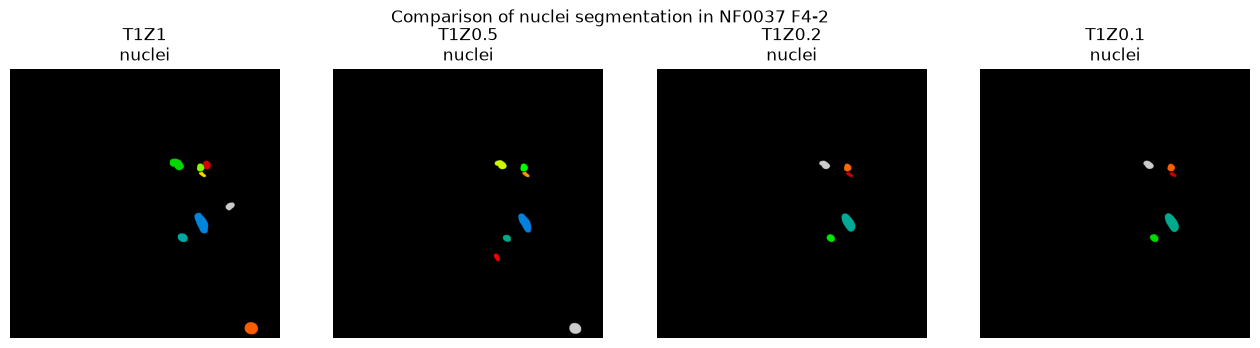

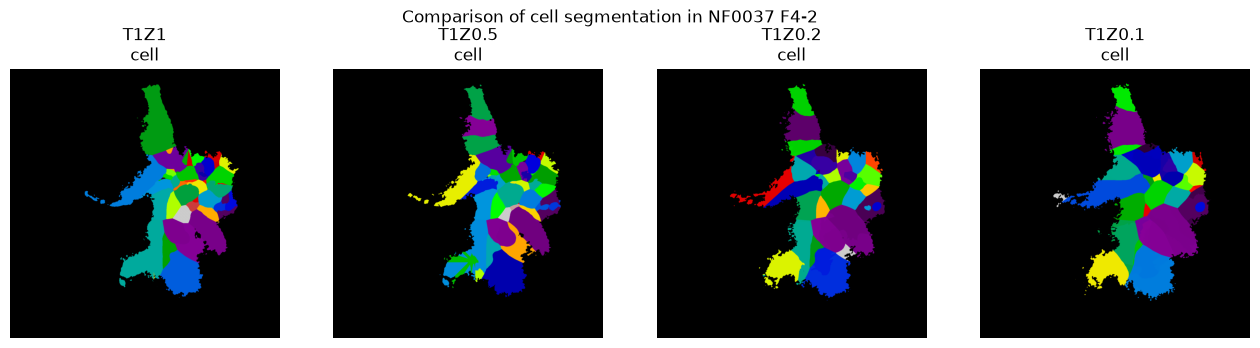

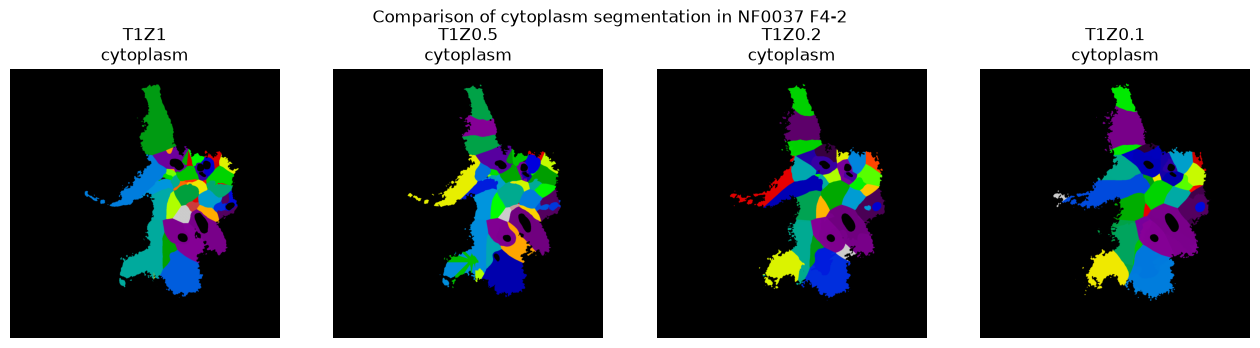

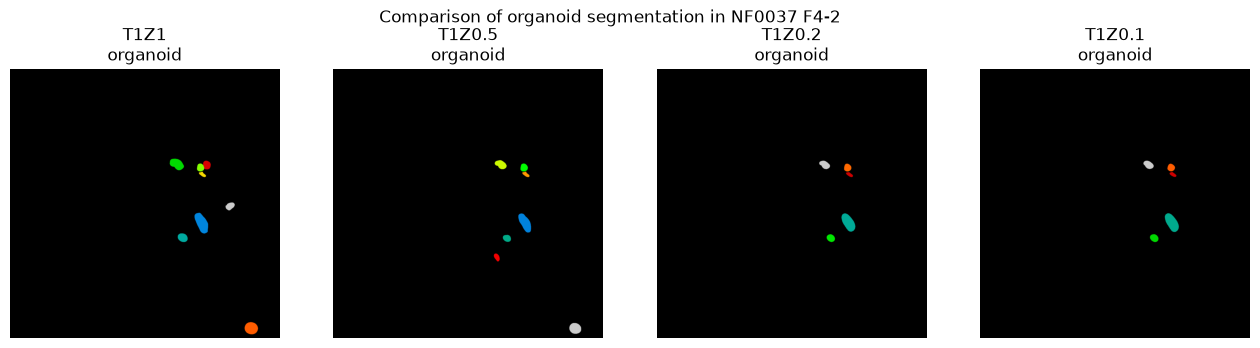

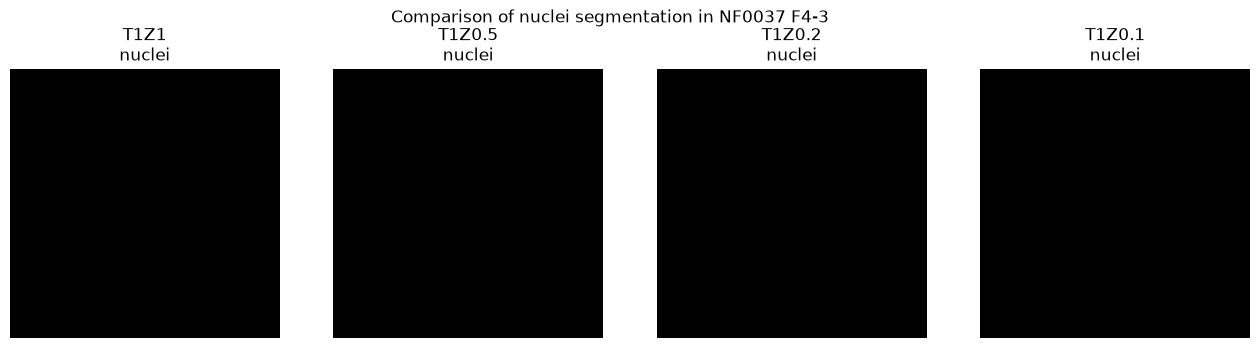

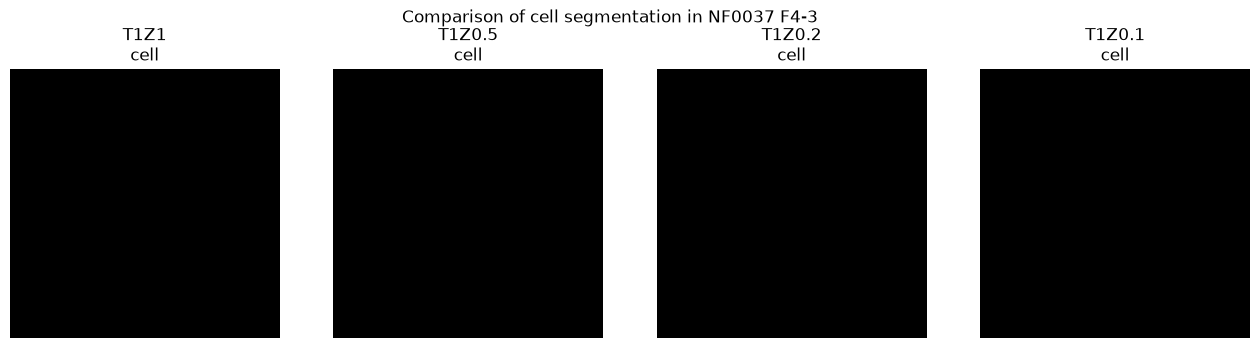

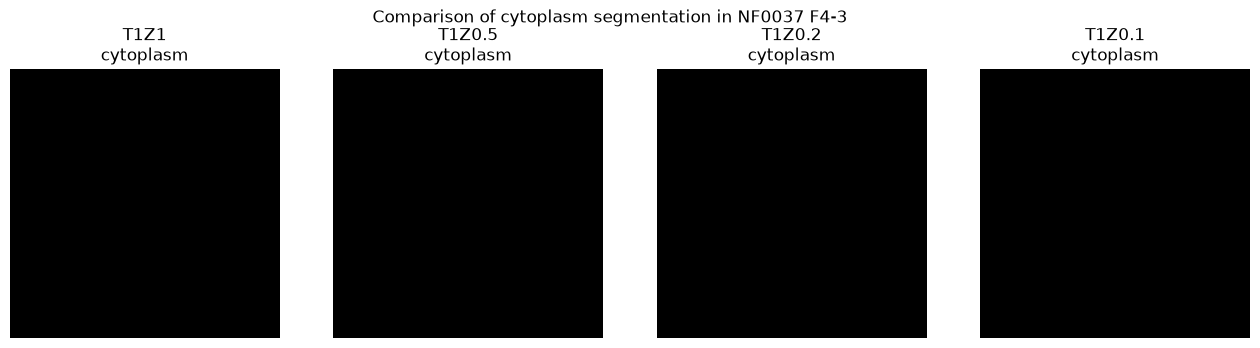

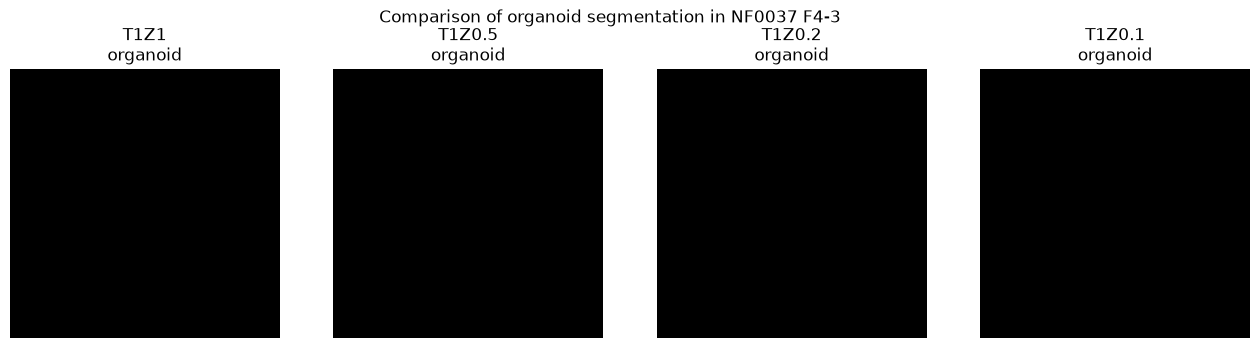

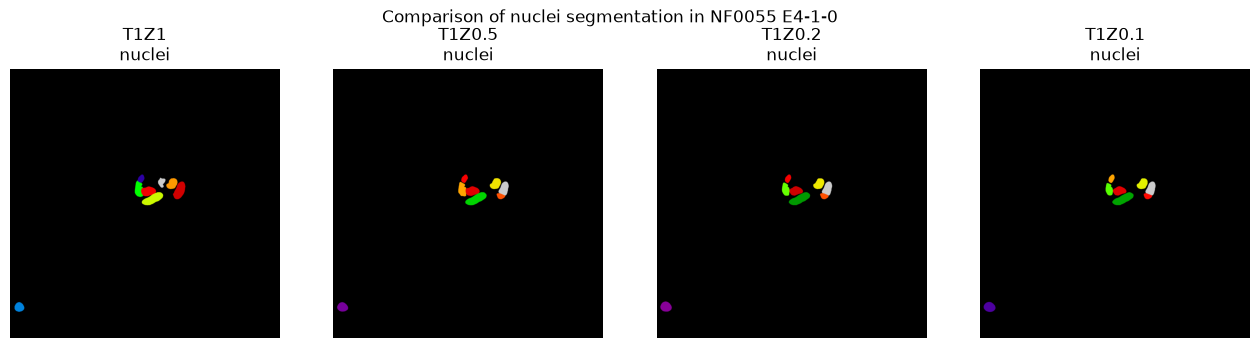

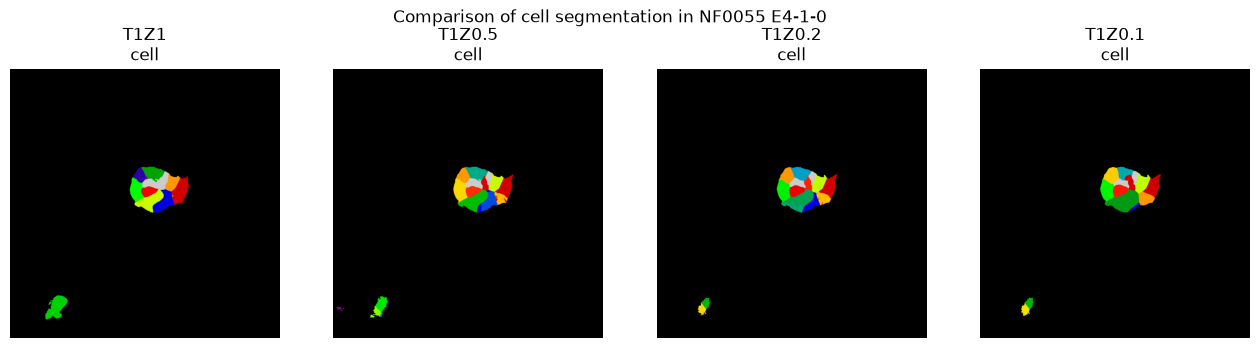

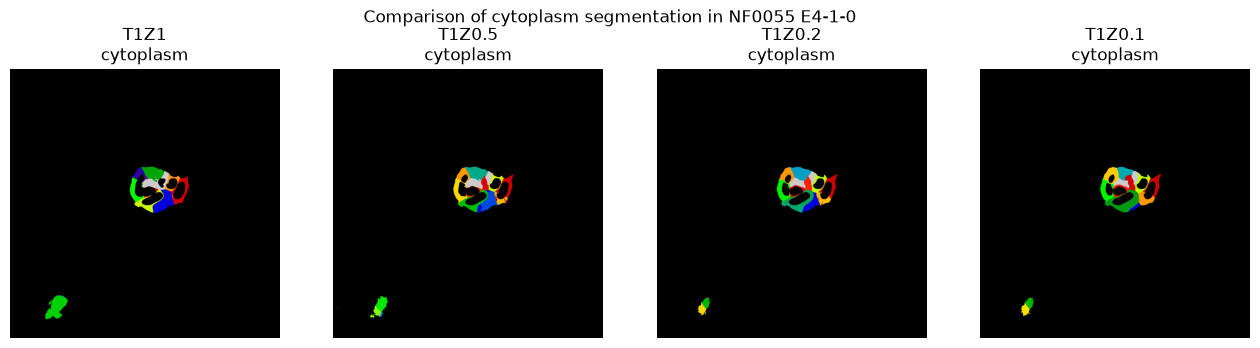

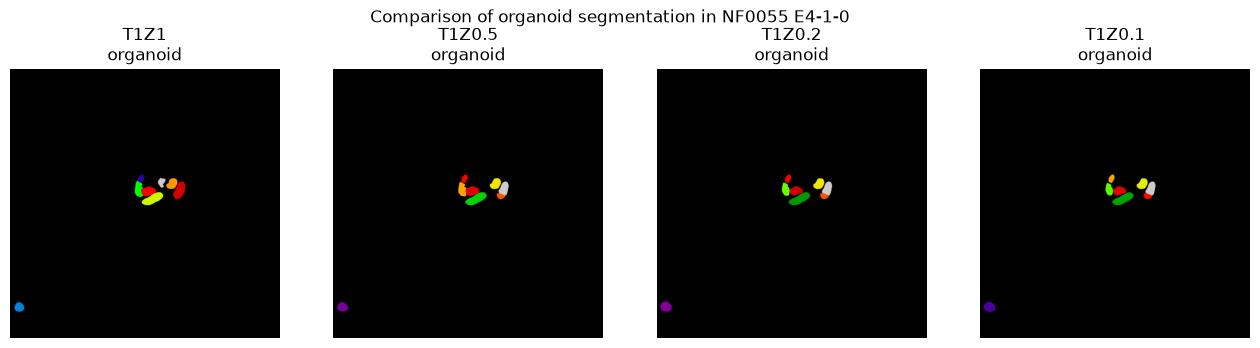

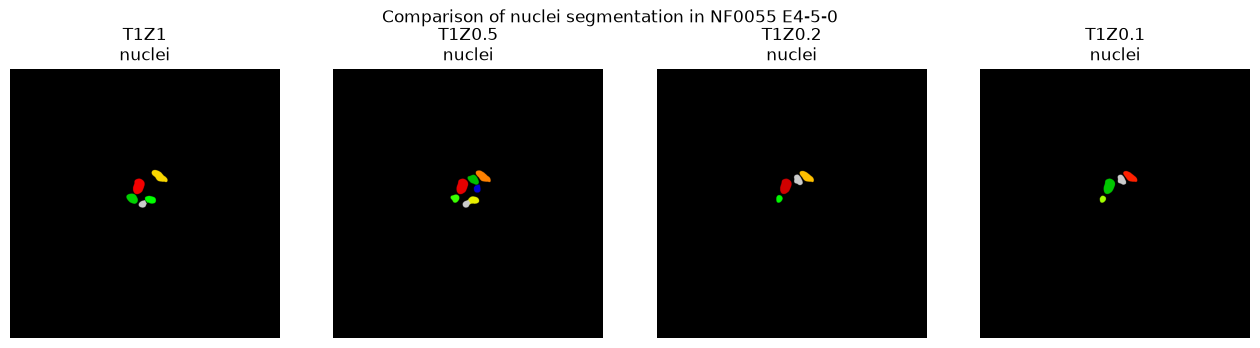

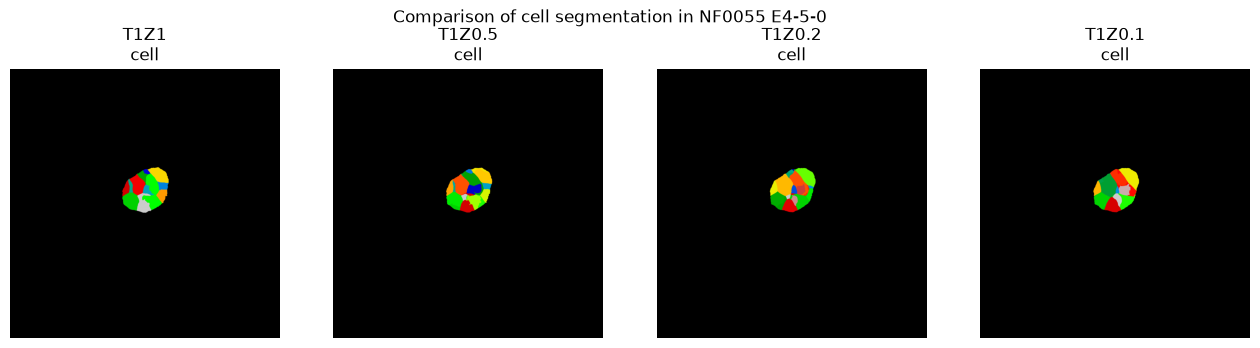

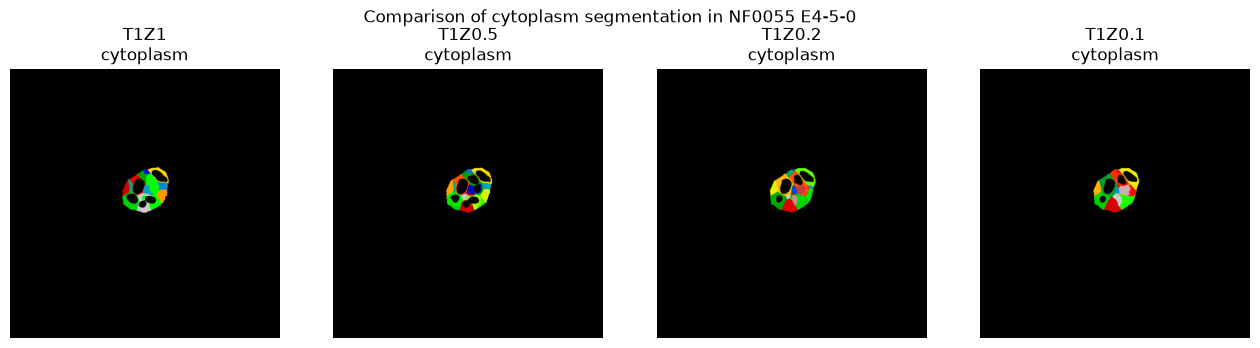

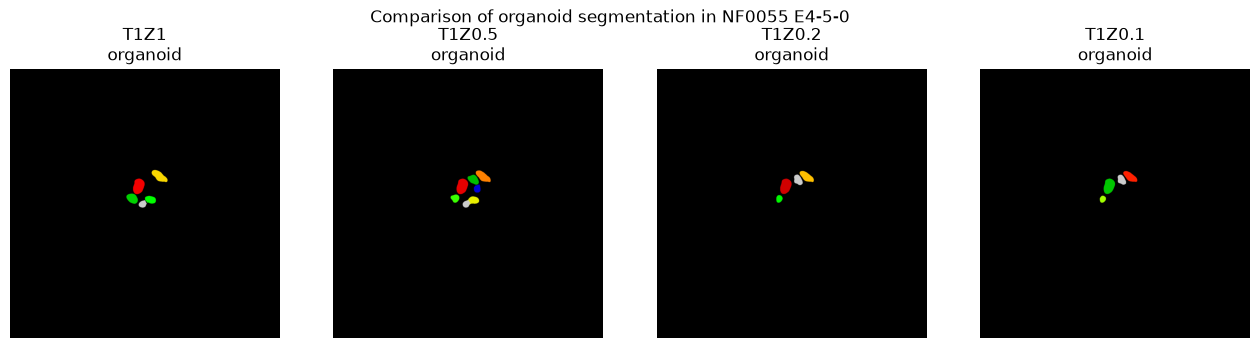

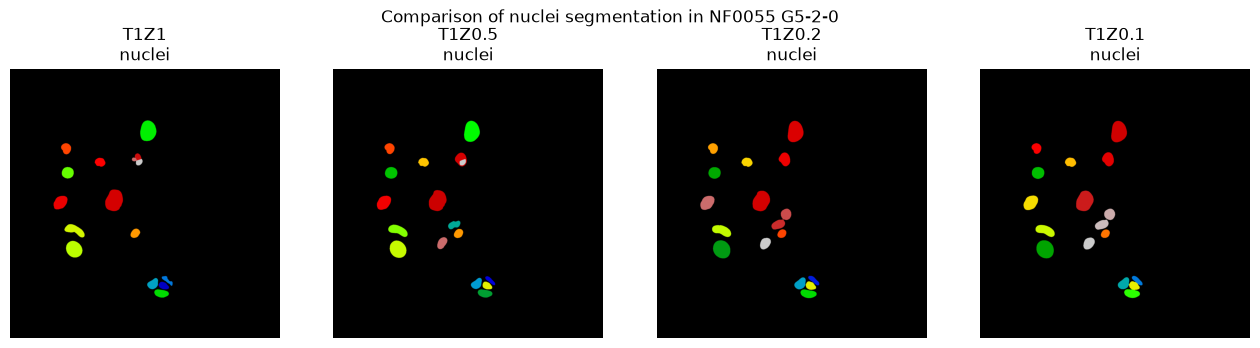

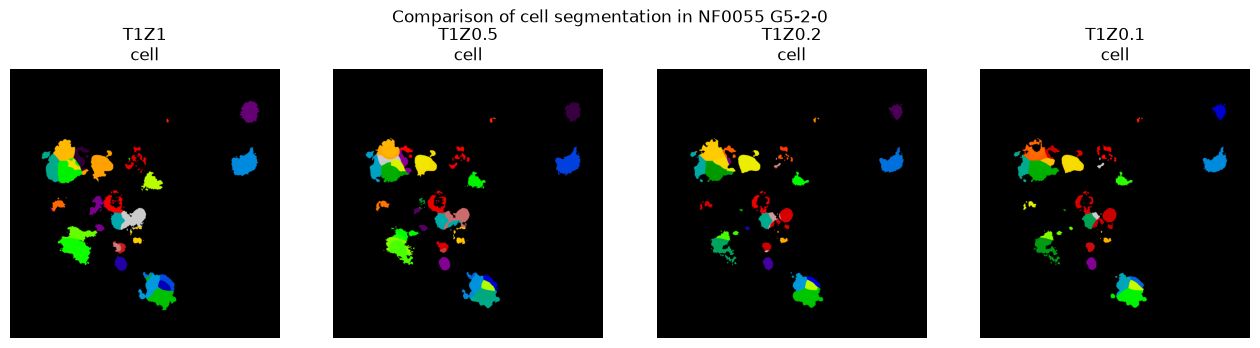

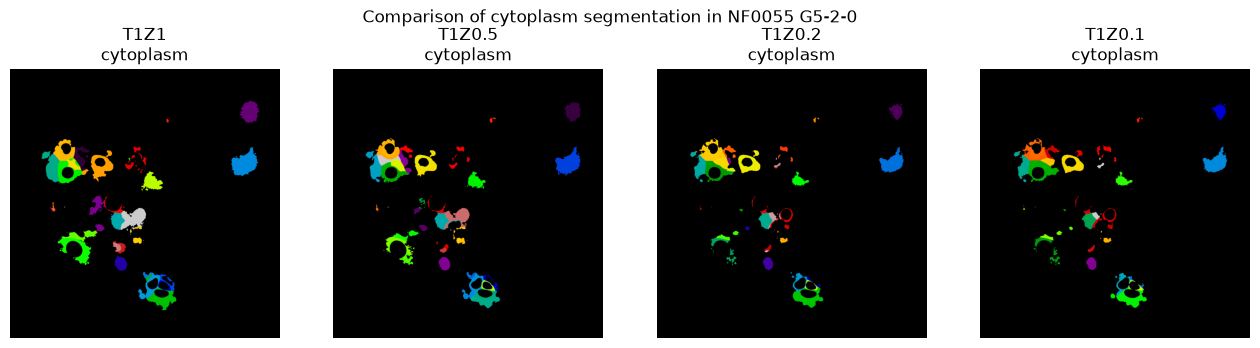

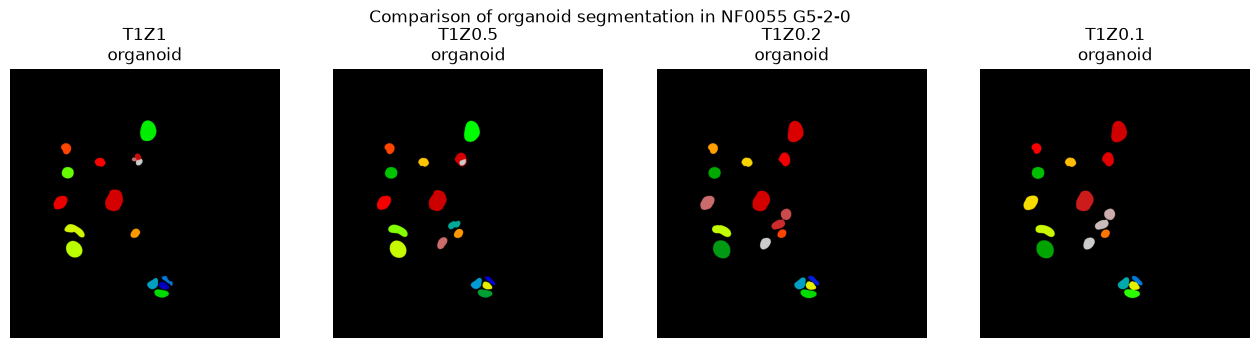

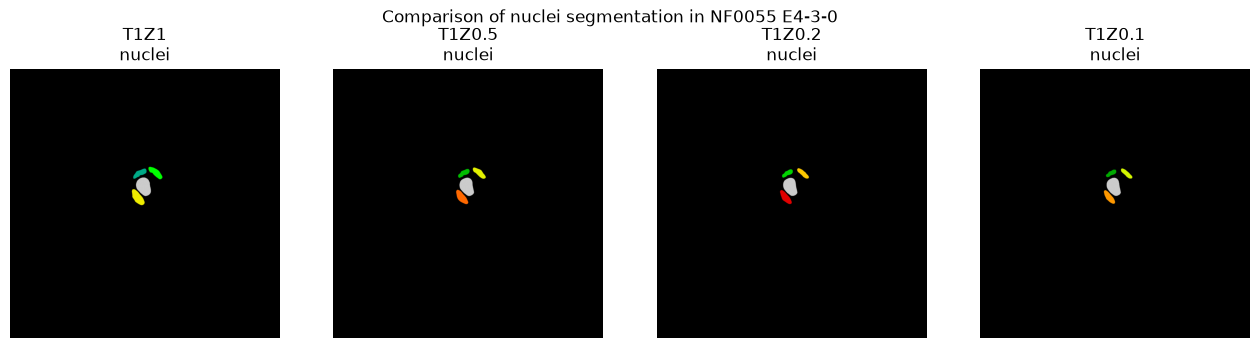

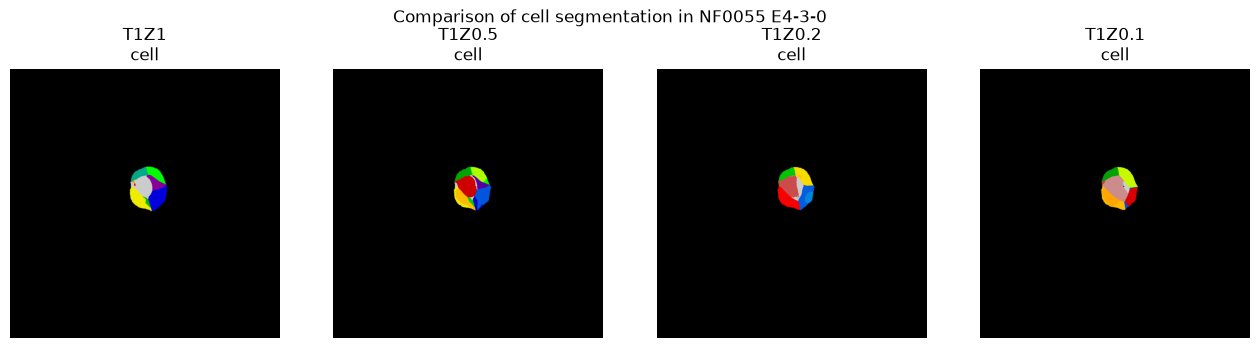

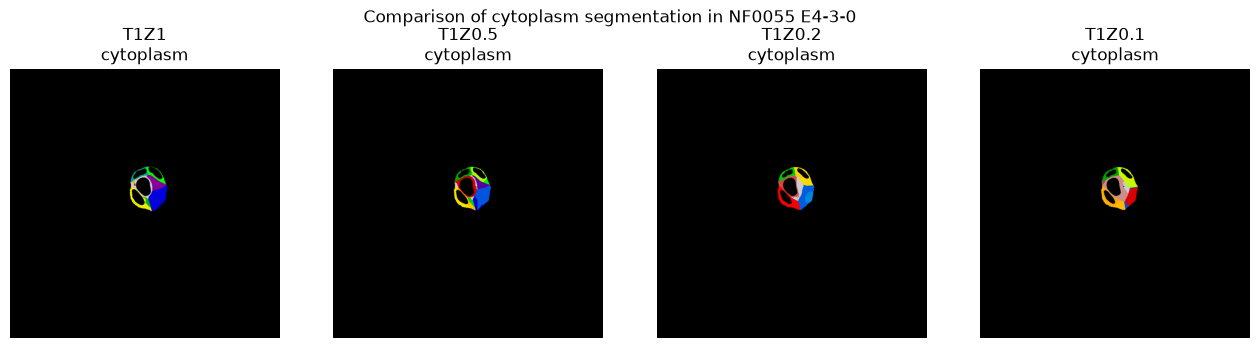

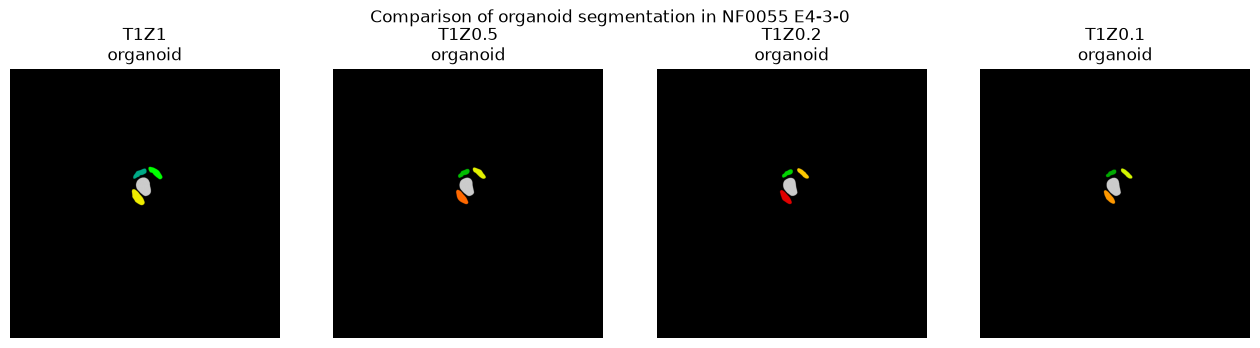

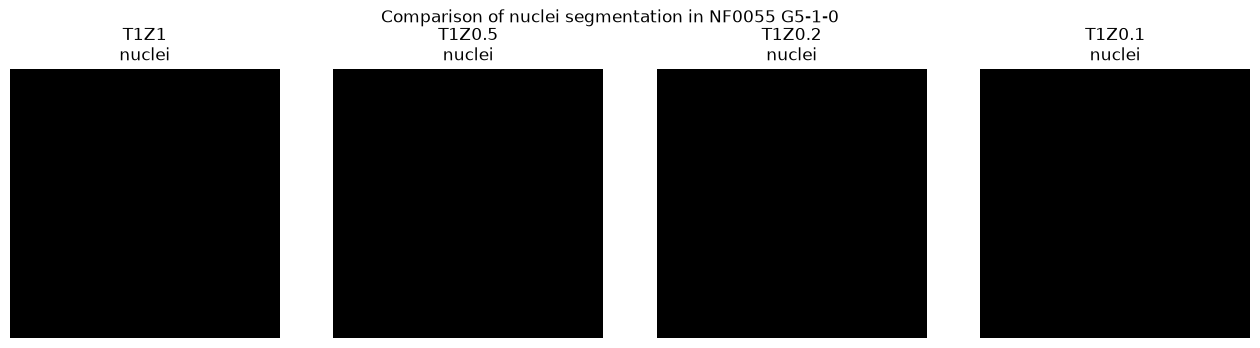

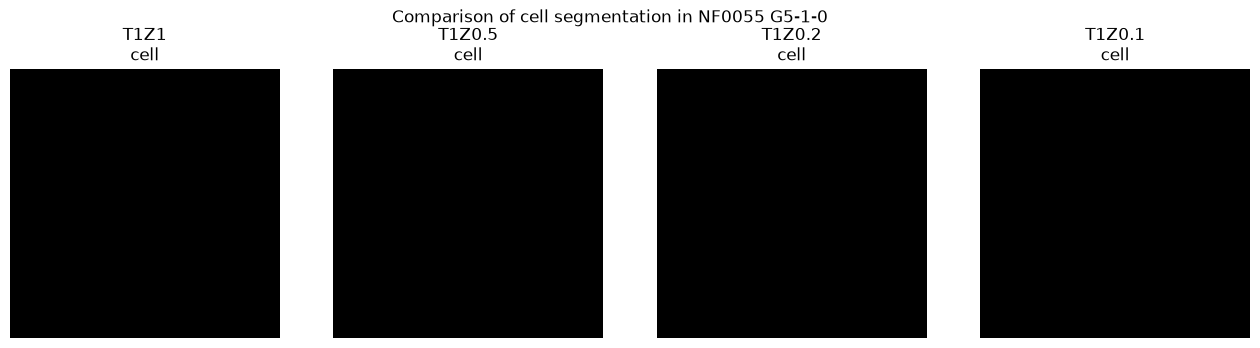

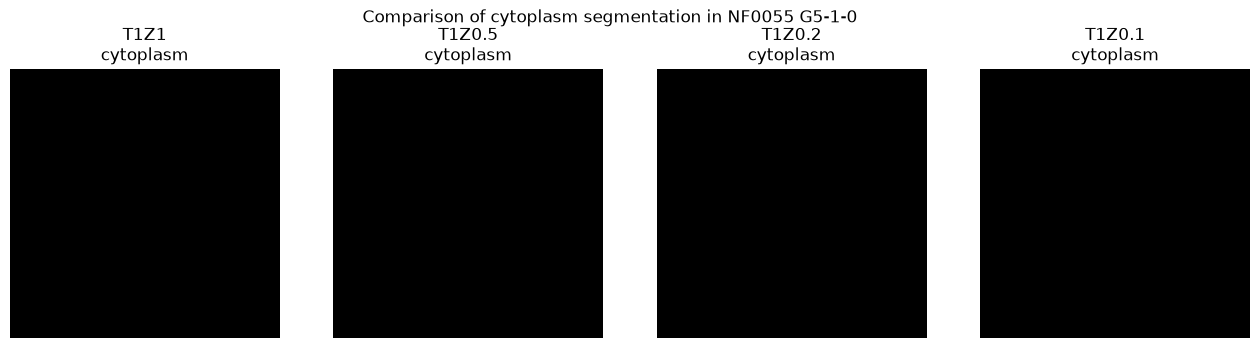

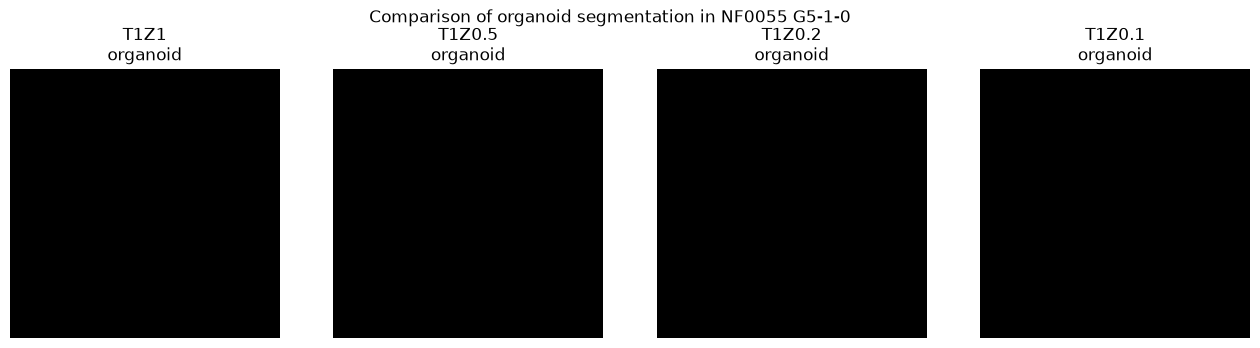

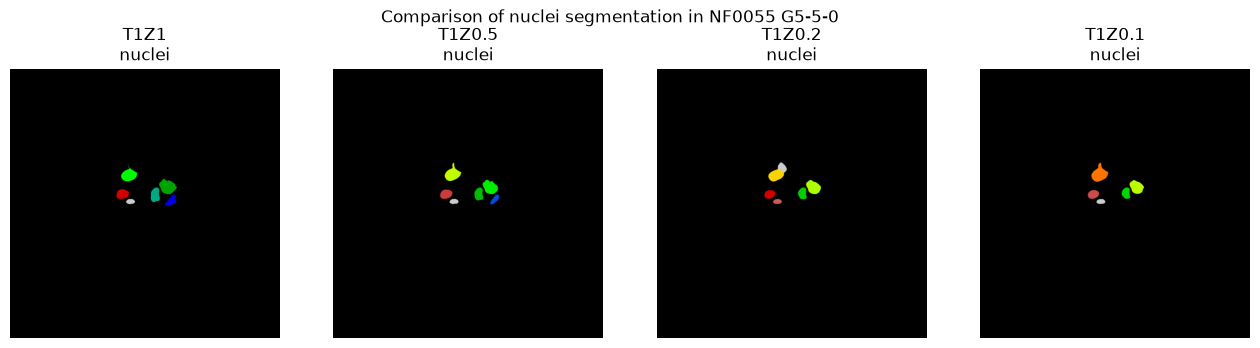

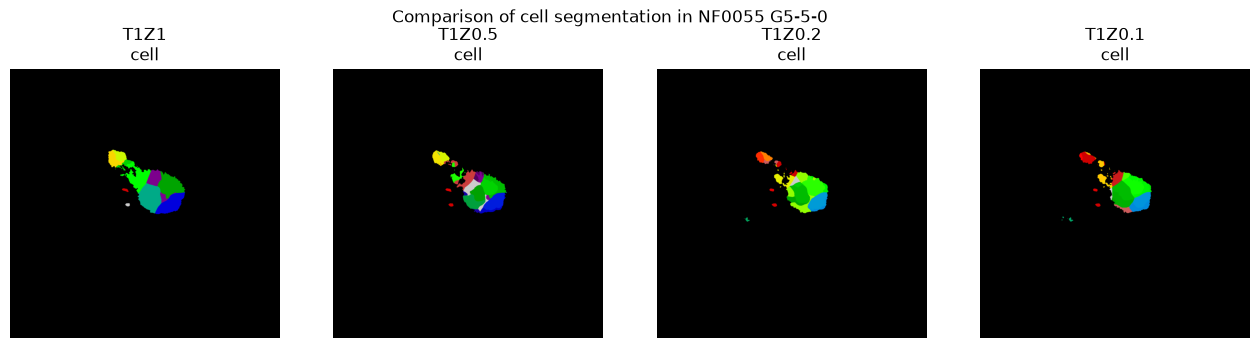

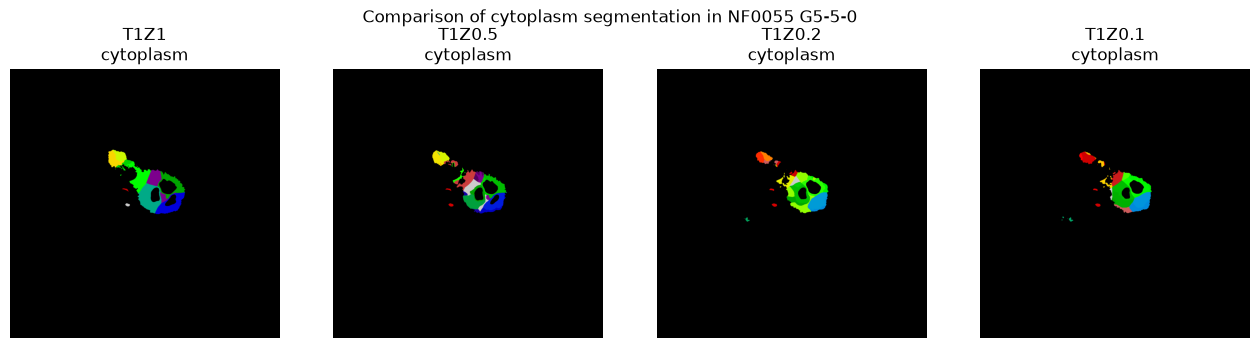

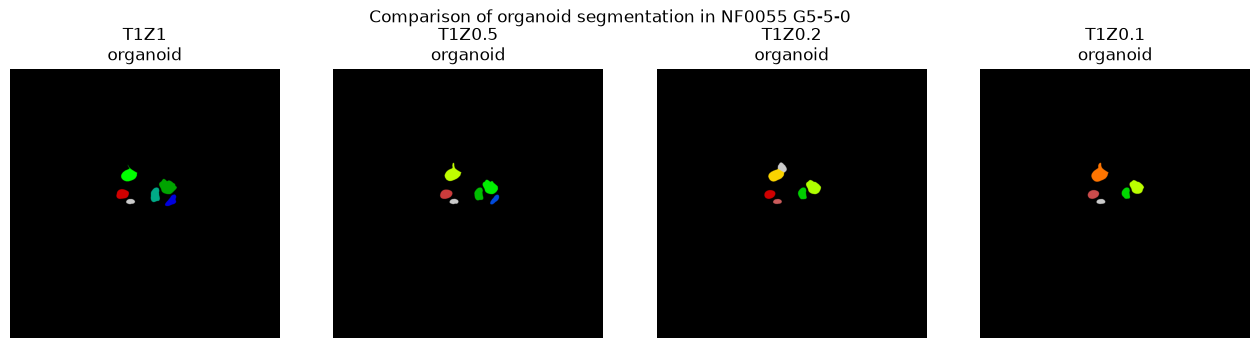

In [4]:
# set eps to avoid division by zero
for patient, well_fovs in tqdm.tqdm(
    patient_well_fovs.items(), desc="Patients", total=len(patient_well_fovs)
):
    for well_fov in well_fovs:
        for compartment in ["nuclei", "cell", "cytoplasm", "organoid"]:
            # load the mask for each z-slice step and sample it down to the
            # same number of z-slices as the finest (T1Z1) step
            mask_dict = {}
            for z_step in z_steps:
                segmentation_dir = (
                    image_base_dir
                    / "data"
                    / f"{patient}_T1-Z-{z_step}"
                    / "segmentation_masks"
                    / well_fov
                )
                mask_file = next(
                    file
                    for file in segmentation_dir.glob("*.tif*")
                    if compartment in str(file)
                )
                mask = read_zstack_image(mask_file)
                stride = z_step_strides[z_step]
                mask_dict[f"T1Z{z_step}"] = mask[::stride, :, :].copy()

            z_slice_counts = {name: mask.shape[0] for name, mask in mask_dict.items()}
            if len(set(z_slice_counts.values())) != 1:
                raise ValueError(
                    "Sampled masks do not have the same number of z-slices in "
                    f"{patient} {well_fov} for {compartment}: {z_slice_counts}"
                )

            # pairwise IOU and volume-ratio comparison across z-slice steps
            for (name1, mask1), (name2, mask2) in combinations(mask_dict.items(), 2):
                iou = extract_IOU(mask1, mask2)
                volume_ratio = mask1.sum() / mask2.sum() if mask2.sum() != 0 else 0
                iou_results["patient"].append(patient)
                iou_results["well_fov"].append(well_fov)
                iou_results["z_comparison"].append(f"{name1} vs {name2}")
                iou_results["IOU"].append(iou)
                iou_results["compartment"].append(compartment)
                iou_results["volume_ratio"].append(volume_ratio)

            # show the masks compared at a representative z-slice
            slice_to_plot = mask_dict["T1Z1"].shape[0] // 2
            # fig, axes = plt.subplots(1, len(mask_dict), figsize=(4 * len(mask_dict), 4))
            # for ax, (name, mask) in zip(axes, mask_dict.items()):
            #     ax.set_title(f"{name}\n{compartment}")
            #     ax.imshow(mask[slice_to_plot, :, :], cmap="nipy_spectral")
            #     ax.axis("off")
            # fig.suptitle(f"Comparison of {compartment} segmentation in {patient} {well_fov}")
            # plt.show()

            # record binarized volume per z-slice step for this compartment
            for name, mask in mask_dict.items():
                binary_mask = convert_indexed_mask_to_binary_mask(mask)
                per_compartment_volume["patient"].append(patient)
                per_compartment_volume["well_fov"].append(well_fov)
                per_compartment_volume["z_slice_step"].append(name)
                per_compartment_volume["compartment"].append(compartment)
                per_compartment_volume["volume"].append(binary_mask.sum())

In [5]:
iou_results_df = pd.DataFrame(iou_results)
per_compartment_volume_df = pd.DataFrame(per_compartment_volume)
# make compartment a categorical variable
iou_results_df["compartment"] = pd.Categorical(
    iou_results_df["compartment"],
    categories=["organoid", "nuclei", "cytoplasm", "cell"],
    ordered=True,
)

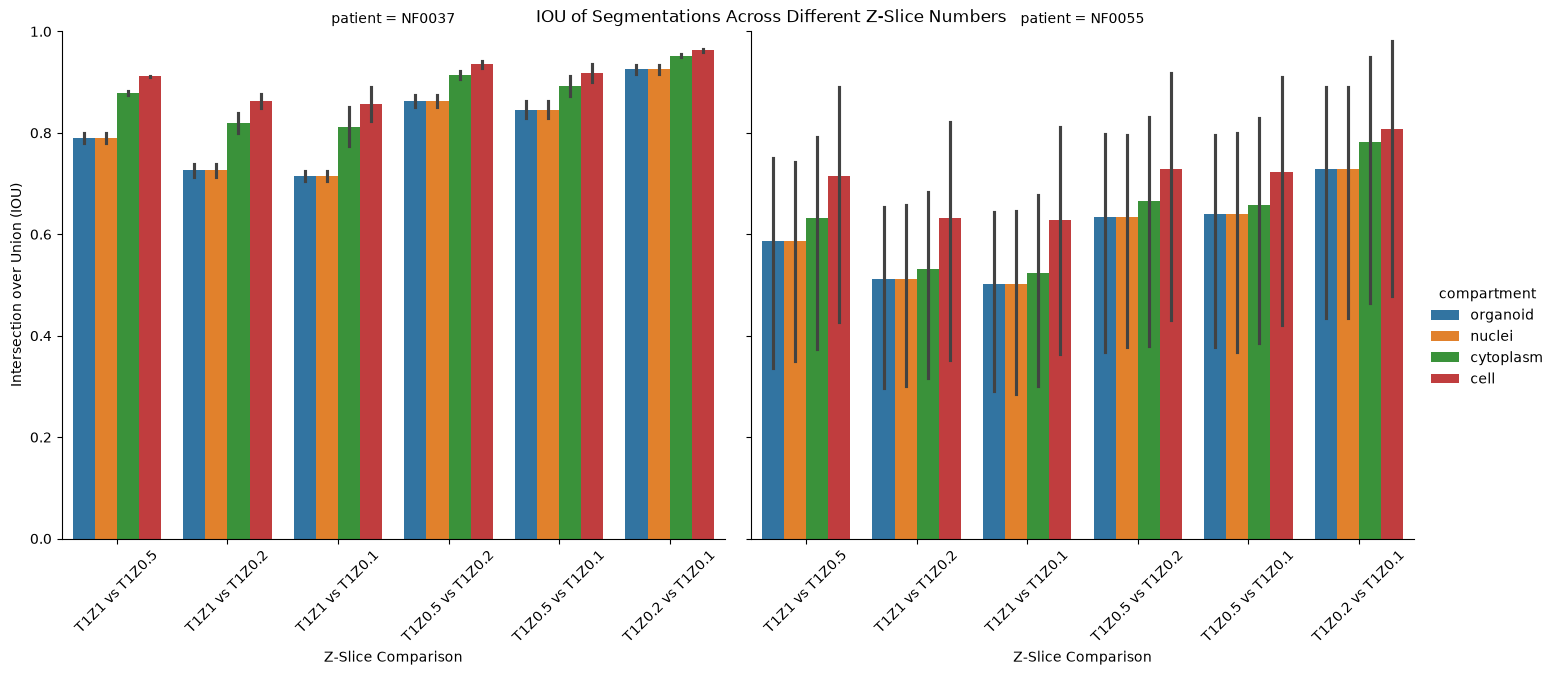

In [6]:
# plot the IOU across z-slice comparisons, faceted by patient to compare
# segmentation stability across patients
g = sns.catplot(
    data=iou_results_df,
    x="z_comparison",
    y="IOU",
    hue="compartment",
    col="patient",
    kind="bar",
    height=6,
    aspect=1.2,
)
g.set_axis_labels("Z-Slice Comparison", "Intersection over Union (IOU)")
g.set(ylim=(0, 1))
g.fig.suptitle("IOU of Segmentations Across Different Z-Slice Numbers")
for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=45)
plt.show()

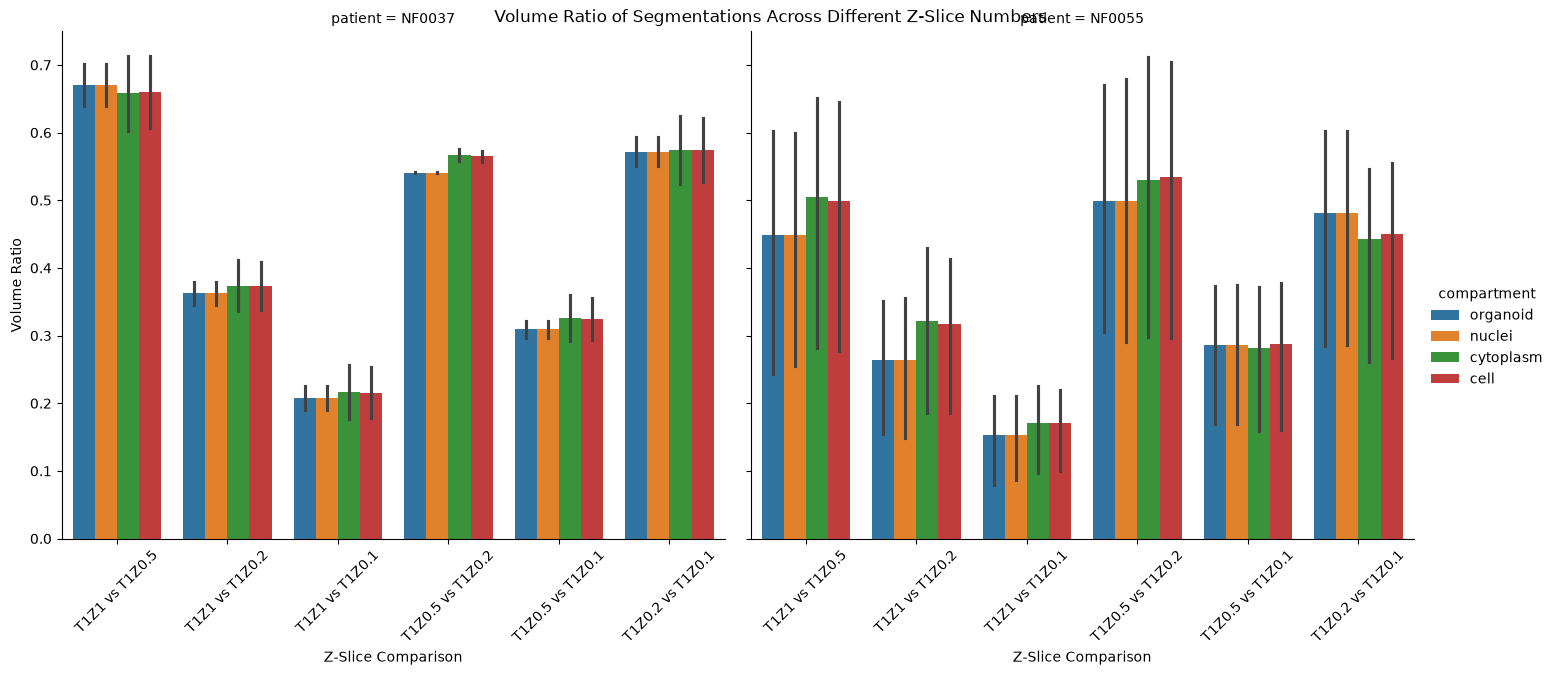

In [10]:
# plot the volume ratio across z-slice comparisons, faceted by patient to
# compare segmentation stability across patients
g = sns.catplot(
    data=iou_results_df,
    x="z_comparison",
    y="volume_ratio",
    hue="compartment",
    col="patient",
    kind="bar",
    height=6,
    aspect=1.2,
)
g.set_axis_labels("Z-Slice Comparison", "Volume Ratio")
# g.set(ylim=(0, 3))
g.fig.suptitle("Volume Ratio of Segmentations Across Different Z-Slice Numbers")
for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=45)
plt.show()

In [8]:
per_compartment_volume_df
# normalize per patient and compartment (min-max normalization), since
# absolute volume scales differ across patients
per_compartment_volume_df["normalized_volume"] = per_compartment_volume_df.groupby(
    ["patient", "compartment"]
)["volume"].transform(lambda x: (x - x.min()) / (x.max() - x.min()))

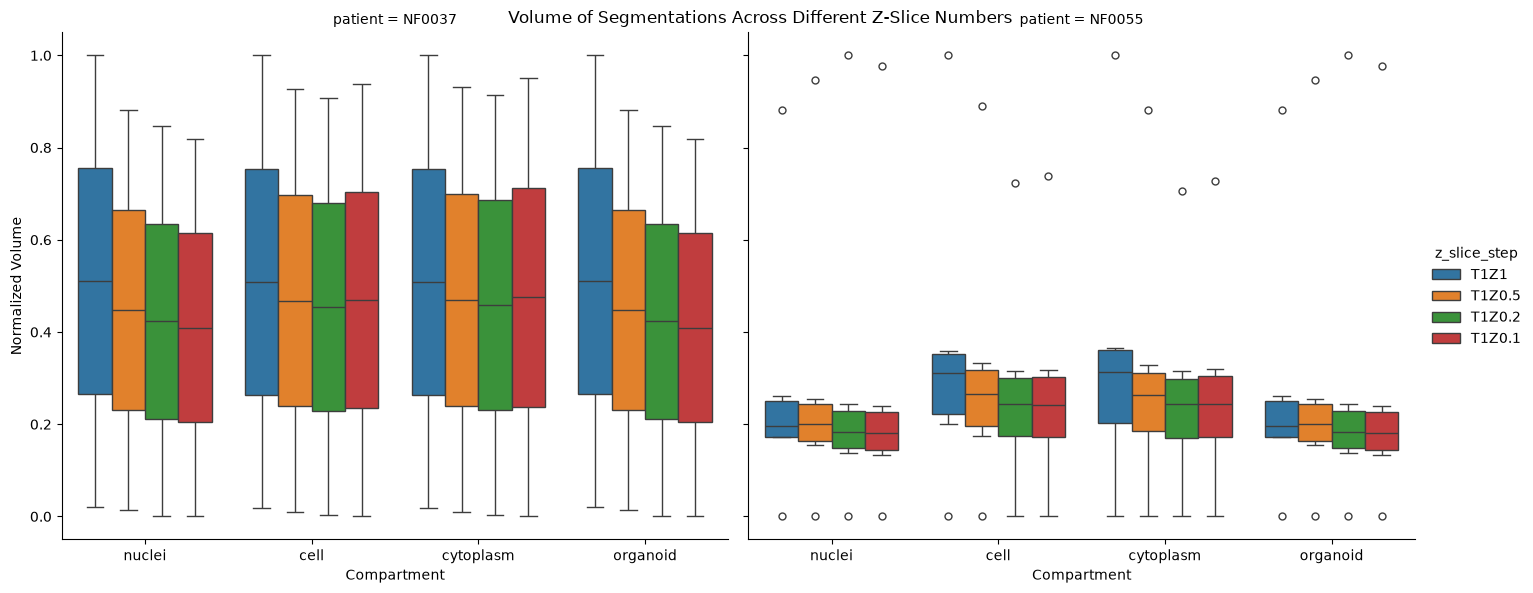

In [9]:
# volume stability across z-slice steps, faceted by patient
g = sns.catplot(
    data=per_compartment_volume_df,
    x="compartment",
    y="normalized_volume",
    hue="z_slice_step",
    col="patient",
    kind="box",
    height=6,
    aspect=1.2,
)
g.set_axis_labels("Compartment", "Normalized Volume")
g.fig.suptitle("Volume of Segmentations Across Different Z-Slice Numbers")
plt.show()